# AIKO-A555-MCE60Mw String Simulation — MPPT & Partial Shading

**Plant:** Four AIKO-A555-MCE60Mw modules in series with bypass diodes, ≈ 2.22 kW at STC.  
**Goal (Stage 1):** Prove the P&O MPPT outer loop tracks the string MPP under a realistic irradiance day and under partial-shading disturbances.

| Spec | Single module | 4-module string |
|---|---|---|
| Panel | AIKO-A555-MCE60Mw (N-type ABC, 120 cells) | 4 × series |
| Pmp (STC) | 555 W | 2220 W |
| Vmp / Voc | 38.70 V / 45.90 V | ~154.8 V / ~183.6 V |
| Imp / Isc | 14.35 A / 14.96 A | 14.35 A (series) |

**Load note:** At ≈ 155 V string MPP, a matched battery load is a **3-series 48 V LiFePO₄ bank** (~128–165 V). For grid-tied operation a boost stage lifts to a 380–400 V DC bus. Stage 1 abstracts the load: P&O commands the string voltage directly and all harvested power is assumed to flow to a downstream sink.

**Author:** Jared Saunders — EGH490-2

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pvlib import pvsystem
from pvlib.ivtools.sdm import fit_desoto_batzelis

## 1 · De Soto parameter fitting — AIKO-A555-MCE60Mw

Single-diode (De Soto) parameters are derived from the datasheet electrical characteristics at STC using `pvlib.ivtools.sdm.fit_desoto_batzelis`. Temperature coefficients from the AIKO Neostar 3P60 datasheet: Isc +0.05 %/°C, Voc −0.22 %/°C, Pmax −0.26 %/°C.

In [2]:
# AIKO-A555-MCE60Mw datasheet values at STC (1000 W/m², 25 °C)
_stc = dict(v_oc=45.90, v_mp=38.70, i_mp=14.35, i_sc=14.96)
_tc  = dict(
    alpha_sc = +0.05e-2 * _stc['i_sc'],   # A/°C  (+0.05 %/°C)
    beta_voc = -0.22e-2 * _stc['v_oc'],   # V/°C  (-0.22 %/°C)
)

AIKO_DESOTO = fit_desoto_batzelis(
    v_mp=_stc['v_mp'], i_mp=_stc['i_mp'],
    v_oc=_stc['v_oc'], i_sc=_stc['i_sc'],
    alpha_sc=_tc['alpha_sc'], beta_voc=_tc['beta_voc'],
)
AIKO_DESOTO.update(EgRef=1.121, dEgdT=-0.0002677)

_DESOTO_KEYS = ('alpha_sc', 'a_ref', 'I_L_ref', 'I_o_ref', 'R_sh_ref', 'R_s', 'EgRef', 'dEgdT')

# --- verify the fit reproduces the datasheet at STC ---
_IL, _I0, _Rs, _Rsh, _nNsVth = pvsystem.calcparams_desoto(
    effective_irradiance=1000, temp_cell=25,
    **{k: AIKO_DESOTO[k] for k in _DESOTO_KEYS},
)
_sd = pvsystem.singlediode(_IL, _I0, _Rs, _Rsh, _nNsVth)

print('AIKO-A555-MCE60Mw — De Soto fit verification (STC: 1000 W/m², 25 °C)')
for label, key, target in [
    ('Pmp [W] ', 'p_mp', 555.00),
    ('Voc [V] ', 'v_oc',  45.90),
    ('Vmp [V] ', 'v_mp',  38.70),
    ('Imp [A] ', 'i_mp',  14.35),
    ('Isc [A] ', 'i_sc',  14.96),
]:
    print(f'  {label}  fit = {_sd[key]:7.3f}   target = {target}')

AIKO-A555-MCE60Mw — De Soto fit verification (STC: 1000 W/m², 25 °C)
  Pmp [W]   fit = 555.584   target = 555.0
  Voc [V]   fit =  45.892   target = 45.9
  Vmp [V]   fit =  38.849   target = 38.7
  Imp [A]   fit =  14.301   target = 14.35
  Isc [A]   fit =  14.960   target = 14.96


## 2 · PVModule — single AIKO-A555-MCE60Mw

`PVModule` wraps the pvlib single-diode model for one panel. Call `set_conditions(G, Tc)` to fix the operating environment, then query `current_at_voltage(v)`, `voltage_at_current(i)` (clamps to 0 when a bypass diode would conduct), or `iv_points()` for a full sweep.

In [3]:
class PVModule:
    '''Single AIKO-A555-MCE60Mw — pvlib single-diode (De Soto) model.'''

    def __init__(self, name='module', params=None):
        self.name       = name
        self._ref       = dict(AIKO_DESOTO if params is None else params)
        self.irradiance = None
        self.temp_cell  = None
        self._params    = None    # cached pvlib params dict
        self.iv_curve   = None    # {v_oc, v_mp, i_mp, i_sc, p_mp}

    def set_conditions(self, irradiance, temp_cell=25.0):
        self.irradiance = max(float(irradiance), 1e-6)
        self.temp_cell  = float(temp_cell)
        IL, I0, Rs, Rsh, nNsVth = pvsystem.calcparams_desoto(
            effective_irradiance=self.irradiance,
            temp_cell=self.temp_cell,
            **{k: self._ref[k] for k in _DESOTO_KEYS},
        )
        self._params = dict(
            photocurrent=IL, saturation_current=I0,
            resistance_series=Rs, resistance_shunt=Rsh,
            nNsVth=nNsVth,
        )
        sd = pvsystem.singlediode(IL, I0, Rs, Rsh, nNsVth)
        self.iv_curve = {k: float(sd[k]) for k in ('v_oc', 'v_mp', 'i_mp', 'i_sc', 'p_mp')}
        return self

    def current_at_voltage(self, v):
        v = float(np.clip(v, 0.0, self.iv_curve['v_oc']))
        i = pvsystem.i_from_v(voltage=v, **self._params, method='lambertw')
        return float(max(i, 0.0))

    def voltage_at_current(self, i):
        '''Returns 0 when bypass diode would conduct (module reverse-biased).'''
        v = pvsystem.v_from_i(current=float(i), **self._params, method='lambertw')
        return float(max(v, 0.0))

    def iv_points(self, n=200):
        '''Return (v_arr, i_arr) across the full IV curve.'''
        v = np.linspace(0.0, self.iv_curve['v_oc'], n)
        i = np.array([self.current_at_voltage(vv) for vv in v])
        return v, i

## 3 · Module IV and P-V curves

Single module IV and power-voltage curves at four irradiance levels. Circles mark the maximum power point (MPP) at each irradiance.

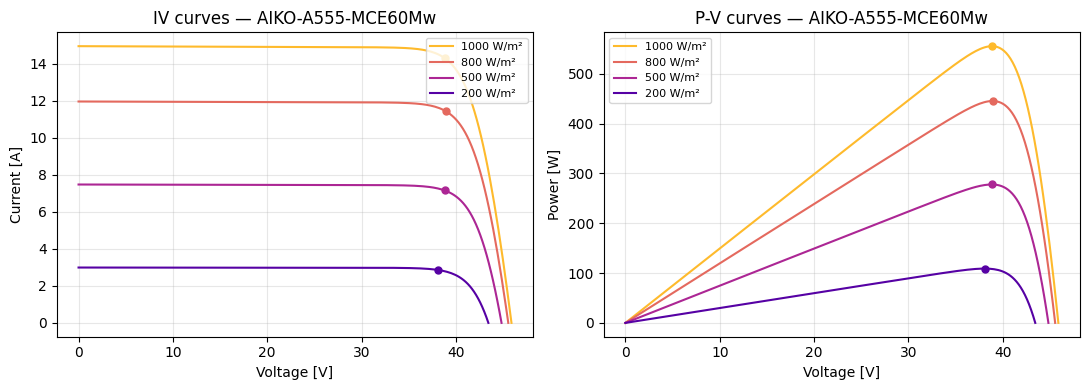

In [4]:
_mod = PVModule()
_G_vals    = [1000, 800, 500, 200]
_iv_colors = plt.cm.plasma_r(np.linspace(0.15, 0.85, len(_G_vals)))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for G, col in zip(_G_vals, _iv_colors):
    _mod.set_conditions(G)
    v, i = _mod.iv_points()
    p = v * i
    iv = _mod.iv_curve
    axes[0].plot(v, i, color=col, label=f'{G} W/m²')
    axes[0].plot(iv['v_mp'], iv['i_mp'], 'o', color=col, ms=5)
    axes[1].plot(v, p, color=col, label=f'{G} W/m²')
    axes[1].plot(iv['v_mp'], iv['p_mp'], 'o', color=col, ms=5)

for ax, ylabel, title in zip(
    axes,
    ['Current [A]', 'Power [W]'],
    ['IV curves', 'P-V curves'],
):
    ax.set_xlabel('Voltage [V]')
    ax.set_ylabel(ylabel)
    ax.set_title(f'{title} — AIKO-A555-MCE60Mw')
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

fig.tight_layout()
plt.show()

## 4 · PVString — 4 modules in series with bypass diodes

The string IV curve is computed by summing each module's voltage at a common current. When the string current exceeds a shaded module's Isc, that module's bypass diode conducts and its voltage contribution is clamped to zero.

This produces a **stepped P-V curve with multiple local maxima** under partial shading — a well-known challenge for hill-climbing MPPT.

`set_conditions(irradiances)` takes a list of four irradiance values (W/m²), one per module. Changing any single value injects a partial-shading disturbance.

**String voltage range:** V_oc ≈ 4 × 45.9 = 183.6 V, V_mp ≈ 4 × 38.7 = 154.8 V.

In [5]:
class PVString:
    '''N PVModule instances in series with bypass diode model.'''

    def __init__(self, n_modules=4, params=None):
        self.modules = [PVModule(f'M{k+1}', params) for k in range(n_modules)]
        self.n       = n_modules
        self._i_arr  = None
        self._v_arr  = None
        self._p_arr  = None

    def set_conditions(self, irradiances, temp_cell=25.0):
        '''irradiances: list of n_modules G values [W/m²].'''
        irradiances = np.asarray(irradiances, dtype=float)
        if len(irradiances) != self.n:
            raise ValueError(f'Expected {self.n} irradiance values, got {len(irradiances)}')
        for mod, G in zip(self.modules, irradiances):
            mod.set_conditions(G, temp_cell)
        self._build_table()
        return self

    def _build_table(self, n_pts=200):
        i_max = max(m.iv_curve['i_sc'] for m in self.modules) * 1.005
        self._i_arr = np.linspace(0.0, i_max, n_pts)
        # Vectorized: one v_from_i call per module across the whole current sweep.
        # A bypassed (reverse-biased) module contributes 0 V, hence the clamp.
        v_total = np.zeros_like(self._i_arr)
        for m in self.modules:
            v = pvsystem.v_from_i(current=self._i_arr, **m._params, method='lambertw')
            v_total += np.maximum(np.nan_to_num(v, nan=0.0), 0.0)
        self._v_arr = v_total
        self._p_arr = self._i_arr * self._v_arr

    @property
    def v_oc(self):
        return float(self._v_arr[0]) if self._v_arr is not None else None

    @property
    def mpp(self):
        idx = int(np.argmax(self._p_arr))
        return dict(
            v_mp=float(self._v_arr[idx]),
            i_mp=float(self._i_arr[idx]),
            p_mp=float(self._p_arr[idx]),
        )

    def current_at_voltage(self, v_string):
        '''String current [A] at given terminal voltage [V], via IV table interpolation.'''
        if self._v_arr is None:
            raise RuntimeError('call set_conditions() first')
        v_string = float(v_string)
        if v_string >= self._v_arr[0]:
            return 0.0
        if v_string <= 0.0:
            return float(self._i_arr[-1])
        # v_arr is monotonically non-increasing; searchsorted on flipped array
        idx = int(np.clip(np.searchsorted(-self._v_arr, -v_string), 1, len(self._v_arr) - 1))
        v1, v2 = self._v_arr[idx - 1], self._v_arr[idx]
        i1, i2 = self._i_arr[idx - 1], self._i_arr[idx]
        if abs(v2 - v1) < 1e-12:
            return float((i1 + i2) / 2)
        return float(i1 + (v_string - v1) * (i2 - i1) / (v2 - v1))

    def power_at_voltage(self, v_string):
        return v_string * self.current_at_voltage(v_string)

    def iv_table(self):
        '''Return (i_arr, v_arr, p_arr) copies from the precomputed table.'''
        return self._i_arr.copy(), self._v_arr.copy(), self._p_arr.copy()

## 5 · String P-V curves under partial shading

Each curve shows the string P-V characteristic when one module is at 200 W/m² while the other three remain at 1000 W/m². Stars mark the global MPP. When a shaded module's bypass diode activates, the string loses that module's voltage and a new lower-voltage peak forms — the three unshaded modules now operate near their individual MPPs.

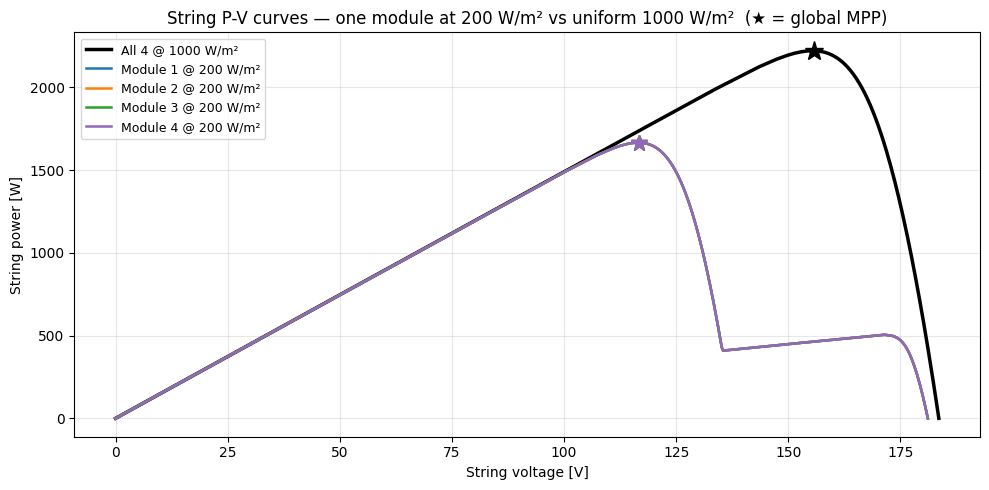

In [6]:
_string_pv = PVString(4)
_shading_cases = [
    ([200, 1000, 1000, 1000], 'Module 1 @ 200 W/m²'),
    ([1000,  200, 1000, 1000], 'Module 2 @ 200 W/m²'),
    ([1000, 1000,  200, 1000], 'Module 3 @ 200 W/m²'),
    ([1000, 1000, 1000,  200], 'Module 4 @ 200 W/m²'),
]
_shade_colors = plt.cm.tab10(np.linspace(0, 0.4, 4))

fig, ax = plt.subplots(figsize=(10, 5))

# Reference — all modules at 1000 W/m²
_string_pv.set_conditions([1000, 1000, 1000, 1000])
_ref_mpp = _string_pv.mpp
_v_ref = np.linspace(0, _string_pv.v_oc, 600)
_p_ref = np.array([_string_pv.power_at_voltage(v) for v in _v_ref])
ax.plot(_v_ref, _p_ref, 'k-', lw=2.5, label='All 4 @ 1000 W/m²')
ax.plot(_ref_mpp['v_mp'], _ref_mpp['p_mp'], 'k*', ms=14, zorder=5)

for (Gs, label), col in zip(_shading_cases, _shade_colors):
    _string_pv.set_conditions(Gs)
    _mpp = _string_pv.mpp
    _v = np.linspace(0, _string_pv.v_oc, 600)
    _p = np.array([_string_pv.power_at_voltage(v) for v in _v])
    ax.plot(_v, _p, color=col, lw=1.8, label=label)
    ax.plot(_mpp['v_mp'], _mpp['p_mp'], '*', color=col, ms=12, zorder=5)

ax.set_xlabel('String voltage [V]')
ax.set_ylabel('String power [W]')
ax.set_title('String P-V curves — one module at 200 W/m² vs uniform 1000 W/m²  (★ = global MPP)')
ax.legend(fontsize=9)
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

## 6 · P&O MPPT controller

Classic Perturb & Observe hill-climb on string voltage. Direction is decided from the sign of ΔP/ΔV between successive samples — robust to irradiance changes between perturbations. `step(v_meas, p_meas)` returns the next voltage setpoint.

In [7]:
class PandO:
    '''Perturb & Observe MPPT — dP/dV hill-climb on string voltage.'''

    def __init__(self, step_v=1.5, v_min=10.0, v_max=200.0):
        self.step_v   = float(step_v)
        self.v_min    = float(v_min)
        self.v_max    = float(v_max)
        self.v_ref    = None
        self._v_prev  = None
        self._p_prev  = None
        self._dir     = +1

    def initialise(self, v_start):
        self.v_ref   = float(np.clip(v_start, self.v_min, self.v_max))
        self._v_prev = None
        self._p_prev = None
        self._dir    = +1
        return self

    def step(self, v_meas, p_meas):
        '''Given latest (V, P) measurement, return the next voltage setpoint.'''
        if self._p_prev is None:
            self._v_prev, self._p_prev = v_meas, p_meas
            self.v_ref = float(np.clip(
                self.v_ref + self._dir * self.step_v, self.v_min, self.v_max))
            return self.v_ref
        dp = p_meas - self._p_prev
        dv = v_meas - self._v_prev
        if abs(dv) < 1e-9:
            self._dir = -self._dir
        elif dp > 0:
            self._dir = +1 if dv > 0 else -1
        else:
            self._dir = -1 if dv > 0 else +1
        self._v_prev, self._p_prev = v_meas, p_meas
        self.v_ref = float(np.clip(
            self.v_ref + self._dir * self.step_v, self.v_min, self.v_max))
        return self.v_ref

## 7 · Stage 1 simulation

`Stage1Sim` runs the P&O MPPT loop on the four-module string. The load is abstracted: P&O commands the string voltage, the string model returns current, and harvested power = V × I flows to a downstream sink.

`irradiance_schedule` accepts either a scalar (all modules equal) or a list of four floats (per-module G) at each timestep — making step-change disturbances trivial to inject.

In [8]:
class Stage1Sim:
    '''PV string + P&O MPPT — Stage 1 (no converter model).'''

    def __init__(self, string, mppt, dt_s=5.0):
        self.string = string
        self.mppt   = mppt
        self.dt_s   = float(dt_s)

    def run(self, irradiance_schedule, temp_cell=25.0):
        '''
        irradiance_schedule : list of n timesteps.
            Each element is a scalar (uniform G) or list of 4 floats (per-module G).
        Returns a dict of history arrays.
        '''
        n = len(irradiance_schedule)
        hist = {k: np.zeros(n) for k in
                ('v_op', 'i_op', 'p_op', 'v_mp', 'p_mp', 'eff', 'e_harvest_kj')}
        hist['G_mod'] = np.zeros((n, self.string.n))   # per-module irradiance
        hist['v_mod'] = np.zeros((n, self.string.n))   # per-module voltage
        hist['p_mod'] = np.zeros((n, self.string.n))   # per-module power

        Gs0 = irradiance_schedule[0]
        if np.isscalar(Gs0):
            Gs0 = [Gs0] * self.string.n
        self.string.set_conditions(Gs0, temp_cell)
        self.mppt.initialise(0.80 * self.string.v_oc)
        v_op = self.mppt.v_ref
        e_kj = 0.0

        for k, Gs in enumerate(irradiance_schedule):
            if np.isscalar(Gs):
                Gs = [Gs] * self.string.n
            self.string.set_conditions(Gs, temp_cell)
            i_op = self.string.current_at_voltage(v_op)   # shared series current
            p_op = v_op * i_op
            e_kj += p_op * self.dt_s / 1000.0

            # Per-module split at the shared string current.
            v_mod = np.array([m.voltage_at_current(i_op) for m in self.string.modules])

            mpp = self.string.mpp
            hist['G_mod'][k]        = Gs
            hist['v_mod'][k]        = v_mod
            hist['p_mod'][k]        = v_mod * i_op
            hist['v_op'][k]         = v_op
            hist['i_op'][k]         = i_op
            hist['p_op'][k]         = p_op
            hist['v_mp'][k]         = mpp['v_mp']
            hist['p_mp'][k]         = mpp['p_mp']
            hist['eff'][k]          = 100.0 * p_op / mpp['p_mp'] if mpp['p_mp'] > 0 else 0.0
            hist['e_harvest_kj'][k] = e_kj

            v_op = self.mppt.step(v_op, p_op)

        return hist

## 8 · Irradiance profile

A smooth bell-shaped 'day' with optional cloud events exercises MPPT acquisition and re-acquisition. For the partial-shading tests individual per-module arrays are constructed directly.

In [9]:
def typical_day(n=600, g_peak=1000.0, g_base=120.0, cloud=True):
    '''Bell-shaped irradiance day [W/m²] with optional cloud events.'''
    t = np.linspace(0, np.pi, n)
    g = g_base + (g_peak - g_base) * np.sin(t) ** 1.5
    if cloud:
        a, b = int(0.45 * n), int(0.55 * n)
        g[a:b] *= 0.45          # main cloud event
        c, d = int(0.70 * n), int(0.74 * n)
        g[c:d] *= 0.70          # brief second cloud
    return g

## 9 · Uniform irradiance — MPPT tracking

Mean MPPT tracking efficiency : 98.11 %
Energy harvested              : 0.9997 kWh


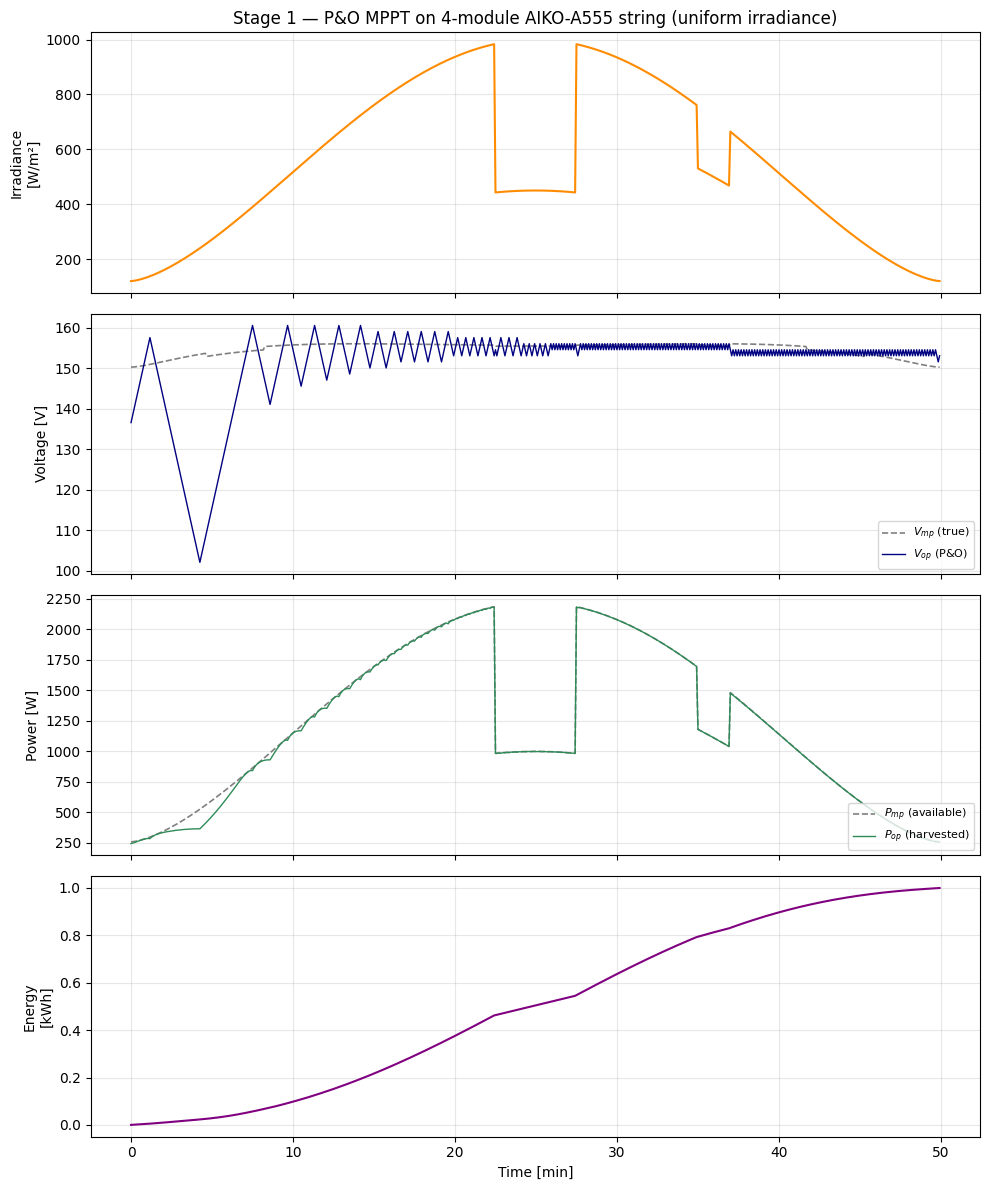

In [10]:
G_day  = typical_day(n=600)
string = PVString(4)
mppt   = PandO(step_v=1.5, v_min=10.0, v_max=200.0)
sim    = Stage1Sim(string, mppt, dt_s=5.0)
h      = sim.run(G_day)

t    = np.arange(len(G_day)) * sim.dt_s / 60.0   # minutes
mask = h['p_mp'] > 10.0

print(f'Mean MPPT tracking efficiency : {h["eff"][mask].mean():.2f} %')
print(f'Energy harvested              : {h["e_harvest_kj"][-1] / 3600.0:.4f} kWh')

fig, axes = plt.subplots(4, 1, figsize=(10, 12), sharex=True)

axes[0].plot(t, h['G_mod'][:, 0], color='darkorange')
axes[0].set_ylabel('Irradiance\n[W/m²]')
axes[0].set_title('Stage 1 — P&O MPPT on 4-module AIKO-A555 string (uniform irradiance)')
axes[0].grid(alpha=0.3)

axes[1].plot(t, h['v_mp'], '--', color='grey', lw=1.2, label='$V_{mp}$ (true)')
axes[1].plot(t, h['v_op'], color='navy', lw=1.0, label='$V_{op}$ (P&O)')
axes[1].set_ylabel('Voltage [V]')
axes[1].legend(loc='lower right', fontsize=8)
axes[1].grid(alpha=0.3)

axes[2].plot(t, h['p_mp'], '--', color='grey', lw=1.2, label='$P_{mp}$ (available)')
axes[2].plot(t, h['p_op'], color='seagreen', lw=1.0, label='$P_{op}$ (harvested)')
axes[2].set_ylabel('Power [W]')
axes[2].legend(loc='lower right', fontsize=8)
axes[2].grid(alpha=0.3)

axes[3].plot(t, h['e_harvest_kj'] / 3600.0, color='purple')
axes[3].set_ylabel('Energy\n[kWh]')
axes[3].set_xlabel('Time [min]')
axes[3].grid(alpha=0.3)

fig.tight_layout()
plt.show()

## 10 · Partial-shading step disturbance — each module in turn

Each subplot runs the string at uniform 1000 W/m² for the first 300 steps (steady-state MPPT), then drops one module to 200 W/m². The dashed line is the true available global MPP power; the solid line is what P&O actually harvests.

**Observation:** After the bypass diode activates, the global MPP shifts to ≈ 116 V (3 × module Vmp). P&O may track this correctly or may get briefly confused by the multi-peak P-V landscape before converging.

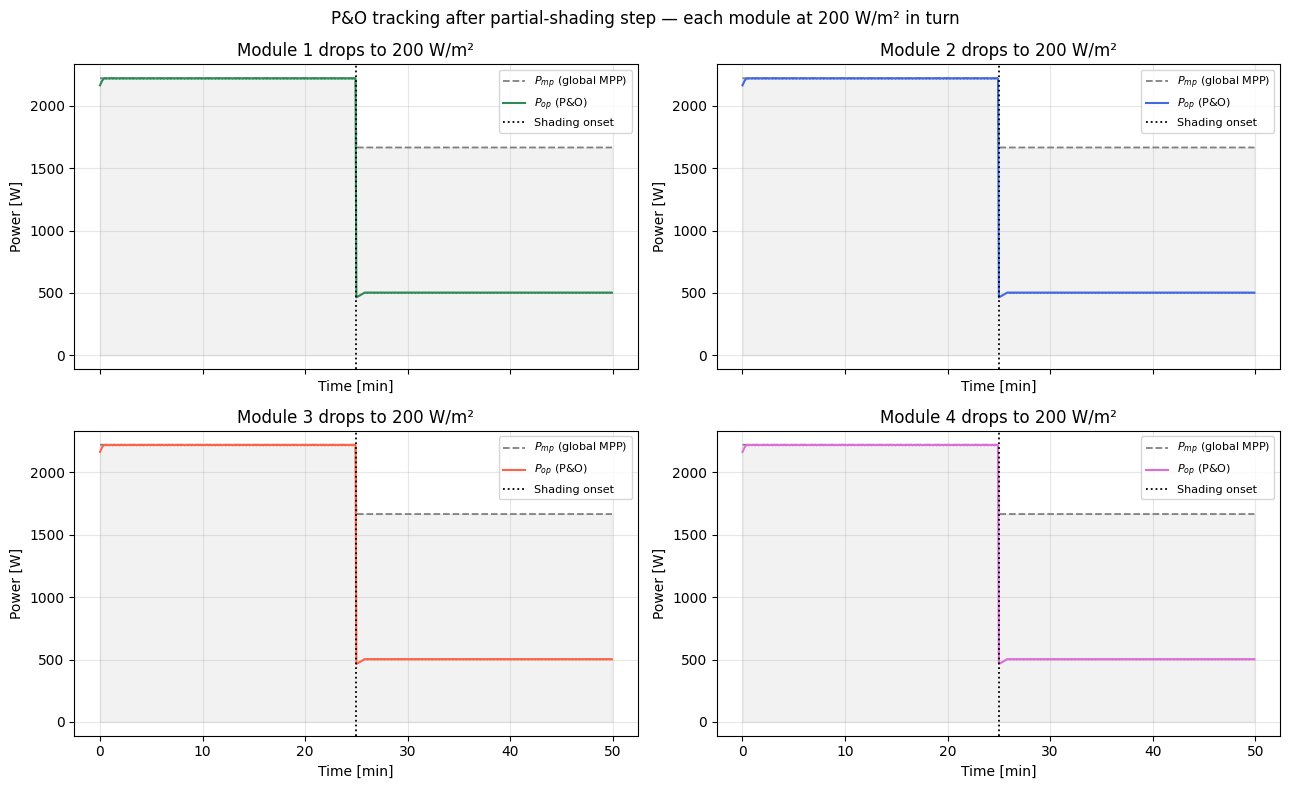

In [11]:
N_FULL  = 300      # steps at uniform 1000 W/m²
N_SHADE = 300      # steps after shading event
G_PEAK  = 1000.0
G_SHADE = 200.0
DT_S    = 5.0      # seconds per step

def _run_shade_scenario(shaded_idx):
    G_full   = [G_PEAK] * 4
    G_shaded = list(G_full)
    G_shaded[shaded_idx] = G_SHADE
    schedule = [G_full] * N_FULL + [G_shaded] * N_SHADE
    str_  = PVString(4)
    mppt_ = PandO(step_v=1.5, v_min=10.0, v_max=200.0)
    sim_  = Stage1Sim(str_, mppt_, dt_s=DT_S)
    return sim_.run(schedule)

_op_colors = ['seagreen', 'royalblue', 'tomato', 'orchid']
t_all   = np.arange(N_FULL + N_SHADE) * DT_S / 60.0   # minutes
t_event = N_FULL * DT_S / 60.0                         # shading onset

fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=True)
axes = axes.ravel()

for i in range(4):
    h   = _run_shade_scenario(i)
    ax  = axes[i]
    ax.fill_between(t_all, h['p_mp'], alpha=0.10, color='grey')
    ax.plot(t_all, h['p_mp'], '--', color='grey', lw=1.3, label='$P_{mp}$ (global MPP)')
    ax.plot(t_all, h['p_op'], color=_op_colors[i], lw=1.5, label='$P_{op}$ (P&O)')
    ax.axvline(t_event, color='k', ls=':', lw=1.3, label='Shading onset')
    ax.set_title(f'Module {i+1} drops to {G_SHADE:.0f} W/m²')
    ax.set_ylabel('Power [W]')
    ax.set_xlabel('Time [min]')
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

fig.suptitle(
    f'P&O tracking after partial-shading step — each module at {G_SHADE:.0f} W/m² in turn',
    fontsize=12,
)
fig.tight_layout()
plt.show()

## 11 · Per-module voltage & current through a disturbance

A single step disturbance — all four modules at 1000 W/m², then **Module 2 drops to 200 W/m²** — resolved down to the individual module level.

**Key fact about a series string:** every module carries the *same* current (the string current). A shading disturbance cannot split the current; it instead reshapes the string P-V curve into **two peaks**:

| Operating point | String V | String I | String P | Module 2 |
|---|---|---|---|---|
| **Global MPP** | ~116 V | ~14.3 A | **~1667 W** | bypass diode conducts, V ≈ 0 |
| **Local peak** | ~172 V | ~2.9 A | ~505 W | current-limits the whole string |

**What P&O actually does here is fail.** Sitting near the *old* MPP (≈ 157 V) when the cloud hits, the hill-climb walks to the **nearer** peak — the high-voltage / low-current local one — and gets stuck. The string collapses to ≈ 500 W even though ≈ 1667 W is available. At this local peak **no bypass diode conducts**: the shaded module simply throttles the shared current down to its own ≈ 3 A, dragging the three healthy modules far off their own MPPs.

This local-maximum trap — visible as the gap between the dashed *available global MPP* and the harvested power below — is precisely the loss the **shuffler** is designed to recover. The panels below show per-module **voltage** (where the redistribution happens), the shared string **current**, and per-module **power**.

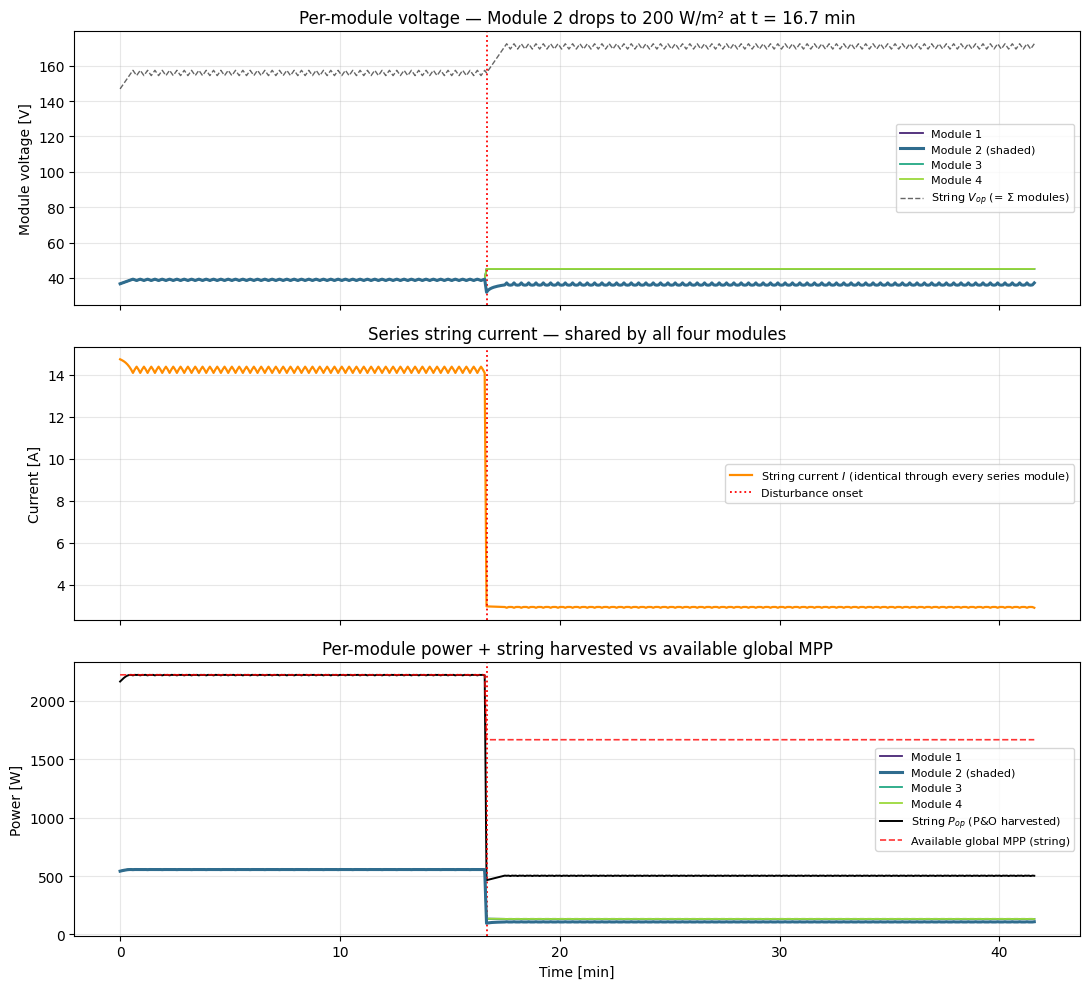

              Mod 1  Mod 2  Mod 3  Mod 4   String
Before  V/V :    39.3   39.3   39.3   39.3    157.4
After   V/V :    45.1   37.2   45.1   45.1    172.4
Before  I/A :   14.09  (shared)
After   I/A :    2.91  (shared)

String power  before :  2217.4 W  (available  2222.3 W)
String power  after  :   502.0 W  (available  1666.7 W)
--> P&O tracking efficiency after disturbance: 30.1%  (local-peak trap — motivates the shuffler)


In [12]:
SHADED_MODULE = 2          # 1-based module index to shade
N_FULL_D  = 200            # steps at uniform 1000 W/m²
N_SHADE_D = 300            # steps after the disturbance
DT_D      = 5.0            # s per step

_G_full   = [1000.0] * 4
_G_shaded = list(_G_full)
_G_shaded[SHADED_MODULE - 1] = 200.0
_schedule = [_G_full] * N_FULL_D + [_G_shaded] * N_SHADE_D

_str  = PVString(4)
_mppt = PandO(step_v=1.5, v_min=10.0, v_max=200.0)
_sim  = Stage1Sim(_str, _mppt, dt_s=DT_D)
hd    = _sim.run(_schedule)

td      = np.arange(N_FULL_D + N_SHADE_D) * DT_D / 60.0   # minutes
t_event = N_FULL_D * DT_D / 60.0
_mcols  = plt.cm.viridis(np.linspace(0.1, 0.85, 4))

fig, axes = plt.subplots(3, 1, figsize=(11, 10), sharex=True)

# --- per-module voltage ---
for m in range(4):
    style = dict(lw=2.2, zorder=4) if (m + 1) == SHADED_MODULE else dict(lw=1.3)
    label = f'Module {m+1}' + (' (shaded)' if (m + 1) == SHADED_MODULE else '')
    axes[0].plot(td, hd['v_mod'][:, m], color=_mcols[m], label=label, **style)
axes[0].plot(td, hd['v_op'], 'k--', lw=1.0, alpha=0.6, label='String $V_{op}$ (= Σ modules)')
axes[0].axvline(t_event, color='r', ls=':', lw=1.3)
axes[0].set_ylabel('Module voltage [V]')
axes[0].set_title(f'Per-module voltage — Module {SHADED_MODULE} drops to 200 W/m² at t = {t_event:.1f} min')
axes[0].legend(loc='center right', fontsize=8)
axes[0].grid(alpha=0.3)

# --- shared string current ---
axes[1].plot(td, hd['i_op'], color='darkorange', lw=1.6,
             label='String current $I$ (identical through every series module)')
axes[1].axvline(t_event, color='r', ls=':', lw=1.3, label='Disturbance onset')
axes[1].set_ylabel('Current [A]')
axes[1].set_title('Series string current — shared by all four modules')
axes[1].legend(loc='center right', fontsize=8)
axes[1].grid(alpha=0.3)

# --- per-module power + available global MPP reference ---
for m in range(4):
    style = dict(lw=2.2, zorder=4) if (m + 1) == SHADED_MODULE else dict(lw=1.3)
    label = f'Module {m+1}' + (' (shaded)' if (m + 1) == SHADED_MODULE else '')
    axes[2].plot(td, hd['p_mod'][:, m], color=_mcols[m], label=label, **style)
axes[2].plot(td, hd['p_op'], 'k-', lw=1.4, label='String $P_{op}$ (P&O harvested)')
axes[2].plot(td, hd['p_mp'], 'r--', lw=1.2, alpha=0.8, label='Available global MPP (string)')
axes[2].axvline(t_event, color='r', ls=':', lw=1.3)
axes[2].set_ylabel('Power [W]')
axes[2].set_xlabel('Time [min]')
axes[2].set_title('Per-module power + string harvested vs available global MPP')
axes[2].legend(loc='center right', fontsize=8)
axes[2].grid(alpha=0.3)

fig.tight_layout()
plt.show()

# --- numeric before/after snapshot ---
_k_before = N_FULL_D - 1
_k_after  = N_FULL_D + N_SHADE_D - 1
print(f'{"":12s}' + ''.join(f'  Mod{m+1:>2d}' for m in range(4)) + '   String')
print(f'Before  V/V : ' + ''.join(f'{hd["v_mod"][_k_before, m]:7.1f}' for m in range(4))
      + f'  {hd["v_op"][_k_before]:7.1f}')
print(f'After   V/V : ' + ''.join(f'{hd["v_mod"][_k_after, m]:7.1f}' for m in range(4))
      + f'  {hd["v_op"][_k_after]:7.1f}')
print(f'Before  I/A : {hd["i_op"][_k_before]:7.2f}  (shared)')
print(f'After   I/A : {hd["i_op"][_k_after]:7.2f}  (shared)')
print()
print(f'String power  before : {hd["p_op"][_k_before]:7.1f} W  '
      f'(available {hd["p_mp"][_k_before]:7.1f} W)')
print(f'String power  after  : {hd["p_op"][_k_after]:7.1f} W  '
      f'(available {hd["p_mp"][_k_after]:7.1f} W)')
print(f'--> P&O tracking efficiency after disturbance: '
      f'{100.0 * hd["p_op"][_k_after] / hd["p_mp"][_k_after]:.1f}%  '
      f'(local-peak trap — motivates the shuffler)')

## 12 · Differential power shuffler — concept & control architecture

Sections 10–11 showed the failure mode the shuffler exists to fix: once one
module is shaded, forcing the **single series string current** through it drives
it into its bypass diode, the string P–V curve grows a second peak, and P&O is
trapped on the wrong one — harvesting far below the power that is physically
available.

A **power shuffler** is a small bidirectional DC–DC converter placed *between two
adjacent modules*. It processes only the **differential power** — the mismatch
between its two neighbours — by pushing a transfer current $t$ from the
higher-current module into the lower-current one. That lets each module carry a
**different** branch current while the string keeps a single terminal current, so
a shaded module no longer has to choose between full string current and full
bypass. Four modules ⇒ **three shufflers** (one per gap).

The control is **two nested PI loops** plus the supervisory MPPT:

| loop | regulated quantity | actuator | reference |
|------|--------------------|----------|-----------|
| **inner** (fast) | the 4 module voltages | the 3 shuffler differential currents $t_j$ | $V_{ref}$ (per-module MPP voltage) |
| **outer** (slow) | string current $I_s$ | the series operating point | $I_{ref}$ = MPP current implied by $V_{ref}$ |
| supervisory | string power | $V_{ref}$ | P&O hill-climb (§6) |

The inner loop only ever *redistributes* current ($\sum_k \Delta i_k = 0$), so the
shufflers move power **between** modules, never add or remove net string power —
the hallmark of differential power processing. Under **uniform** irradiance there
is no mismatch, the differential currents collapse to zero and the shufflers
switch **off**, leaving the bare string at its MPP.

In [13]:
class Shuffler:
    '''One differential power processor bridging modules (k, k+1).

    Sensorless of the rest of the string: it only ever sees its own two module
    voltages and the shared string current. It carries a bidirectional transfer
    current ``t`` (the *differential* current it pushes from the higher-current
    module into the lower-current one) and processes only the differential power
    ``|t| * V_pair``. Slew- and magnitude-limited like a real converter.
    '''
    def __init__(self, name, i_max=11.0, slew=0.10):
        self.name = name
        self.i_max = float(i_max)
        self.slew = float(slew)
        self.t = 0.0
        self.v_left = self.v_right = 0.0
        self.i_string = 0.0

    def reset(self):
        self.t = 0.0
        return self

    def sense(self, v_left, v_right, i_string):
        self.v_left, self.v_right, self.i_string = v_left, v_right, i_string

    def command(self, t_cmd):
        '''Drive the transfer current toward t_cmd within slew & magnitude limits.'''
        t_cmd = float(np.clip(t_cmd, -self.i_max, self.i_max))
        self.t += float(np.clip(t_cmd - self.t, -self.slew, self.slew))
        return self.t

    @property
    def power(self):
        return abs(self.t) * 0.5 * (self.v_left + self.v_right)


class VoltageEqualizer:
    '''Inner control loop — a bank of PI regulators, one per module, that drive
    every module voltage onto the common MPPT reference V_ref. The per-module
    current corrections are made differential (Σ = 0) so the shufflers only move
    power *between* modules, never add or remove net string current.'''
    def __init__(self, n, kp=0.18, ki=0.10, db_engage=1.5, db_park=6.0,
                 i_max=11.0, settle_tol=0.15, settle_hold=20):
        self.n = n
        self.kp, self.ki = float(kp), float(ki)
        self.db_engage = float(db_engage)      # mismatch [V] that engages the loop
        self.db_park = float(db_park)          # only park once spread is below this
        self.i_max = float(i_max)
        self.settle_tol = float(settle_tol)    # |Δinj| below which the loop is "settled"
        self.settle_hold = int(settle_hold)    # consecutive settled steps before parking
        self.integ = np.zeros(n)
        self._inj_prev = np.zeros(n)
        self._settle = 0
        self.active = False

    def reset(self):
        self.integ[:] = 0.0
        self._inj_prev[:] = 0.0
        self._settle = 0
        self.active = False
        return self

    def update(self, v_mod, v_ref, dt):
        # Engage on a real mismatch; once the differential currents stop changing
        # (the string is as equalised as the shufflers can make it) park the loop.
        # The shaded module sits near its steep Isc knee, where a tiny residual
        # ripple would otherwise wag its voltage; freezing the settled command
        # holds a clean steady operating point.
        spread = float(v_mod.max() - v_mod.min())
        if spread > self.db_engage:
            if not self.active:
                self.active = True
                self._settle = 0
        e = v_mod - v_ref                      # module too low (over-driven) => e<0
        if self.active:
            self.integ += self.ki * e * dt
            self.integ = np.clip(self.integ, -self.i_max, self.i_max)
            inj_des = self.kp * e + self.integ
            # Only count as "settled" when the command has stopped moving AND the
            # string is genuinely equalised (no bypassed module) -- otherwise a
            # saturated integrator on a bypassed module would falsely look settled.
            settled = (np.max(np.abs(inj_des - self._inj_prev)) < self.settle_tol
                       and spread < self.db_park and float(v_mod.min()) > 2.0)
            self._settle = self._settle + 1 if settled else 0
            if self._settle >= self.settle_hold:
                self.integ = inj_des.copy()    # absorb P term -> bumpless freeze
                self.active = False
        else:
            inj_des = self.integ.copy()         # parked: hold the equalising split
        self._inj_prev = inj_des.copy()
        inj = inj_des - inj_des.mean()          # enforce differential (zero net) current
        return inj, self.active

## 13 · `ShufflerSim` — the nested-PI plant

`ShufflerSim` wires the two loops to the §4 `PVString`. Each step:

1. **Plant** — the three shuffler transfer currents set the four module branch
   currents $I_k = I_s + \Delta i_k$ (with $\sum_k \Delta i_k = 0$); the
   single-diode model returns each module voltage.
2. **Inner loop** — `VoltageEqualizer` reads the module voltages and commands the
   shufflers' differential currents toward $V_{ref}$.
3. **Outer loop** — a string-current PI slews $I_s$ onto $I_{ref}$, the mean
   module current achievable at $V_{ref}$ (the MPP current — uses the MPPT *V* and
   *I*).
4. **Supervisory** — optional P&O nudges $V_{ref}$ to hill-climb string power.

`shufflers_on=False` re-runs the identical plant with the shufflers disabled — the
bypass-only baseline used for comparison.

In [14]:
class ShufflerSim:
    '''4-module string + 3 differential shufflers under nested PI control.

      outer loop  : string-current PI  -> sets series current i_s onto the MPP
                    current implied by the MPPT voltage (uses MPPT V & I).
      inner loop  : VoltageEqualizer   -> drives every module to V_ref by
                    commanding the 3 shufflers' differential currents.
    '''
    def __init__(self, string, shufflers, equalizer, dt_s=0.1,
                 kp_i=0.05, ki_i=0.6, mppt_step_v=1.0, mppt_every=40,
                 v_margin=1.2):
        self.string = string
        self.shufflers = shufflers
        self.eq = equalizer
        self.dt = float(dt_s)
        self.v_margin = float(v_margin)   # bias V_ref above Vmp for Isc headroom
        self.kp_i, self.ki_i = float(kp_i), float(ki_i)
        self.mppt_step_v = float(mppt_step_v)
        self.mppt_every = int(mppt_every)
        self.n = string.n

    @staticmethod
    def _inj_from_transfers(t, i_s, n):
        inj = np.zeros(n)
        inj[0] = -t[0]
        for k in range(1, n - 1):
            inj[k] = t[k - 1] - t[k]
        inj[-1] = t[-1]
        return i_s + inj, inj

    @staticmethod
    def _transfers_from_inj(inj):
        # t_j = -(inj[0] + ... + inj[j]); valid because sum(inj)=0
        return -np.cumsum(inj)[:-1]

    def run(self, schedule, temp_cell=25.0, shufflers_on=True):
        steps = len(schedule)
        H = {k: np.zeros(steps) for k in
             ('i_s', 'i_ref', 'v_string', 'p_string', 'p_avail', 'v_ref',
              'eff', 'p_shuf', 'active')}
        H['v_mod'] = np.zeros((steps, self.n))
        H['i_mod'] = np.zeros((steps, self.n))
        H['t'] = np.zeros((steps, len(self.shufflers)))

        Gs0 = schedule[0]
        Gs0 = [Gs0] * self.n if np.isscalar(Gs0) else Gs0
        self.string.set_conditions(Gs0, temp_cell)
        mpp = self.string.mpp
        v_base = mpp['v_mp'] / self.n     # MPPT-tracked per-module reference
        shading = False                   # latched from the equaliser activity
        v_ref = v_base
        i_s = mpp['i_mp']
        oint = i_s
        self.eq.reset()
        for s in self.shufflers:
            s.reset()
        po_dir, p_prev, v_prev = +1, None, None
        i_sc_max = 1.05 * max(m.iv_curve['i_sc'] for m in self.string.modules)

        for k, Gs in enumerate(schedule):
            Gs = [Gs] * self.n if np.isscalar(Gs) else Gs
            self.string.set_conditions(Gs, temp_cell)

            # ---- plant: module currents from shuffler transfer currents ----
            t = np.array([s.t for s in self.shufflers]) if shufflers_on \
                else np.zeros(len(self.shufflers))
            i_mod, inj = self._inj_from_transfers(t, i_s, self.n)
            i_mod = np.clip(i_mod, 0.0, None)
            v_mod = np.array([m.voltage_at_current(im)
                              for m, im in zip(self.string.modules, i_mod)])
            v_string = v_mod.sum()
            p_string = i_s * v_string
            mpp = self.string.mpp

            # Reference: per-module MPP voltage, biased up by v_margin only while
            # shading is present, to hold the weak module a margin off its Isc
            # cliff. Under uniform irradiance the bias is absent -> true MPP.
            v_ref = v_base + (self.v_margin if shading else 0.0)

            # ---- inner loop: voltage equaliser commands the shufflers ----
            active = False
            if shufflers_on:
                inj_cmd, active = self.eq.update(v_mod, v_ref, self.dt)
                t_cmd = self._transfers_from_inj(inj_cmd)
                for j, s in enumerate(self.shufflers):
                    s.sense(v_mod[j], v_mod[j + 1], i_s)
                    s.command(t_cmd[j])
                # "shading present" = shufflers are carrying differential current.
                # Tracking this (not the equaliser's engaged/parked state) keeps the
                # V_ref margin steady while the loop is parked, so it doesn't toggle.
                shading = max(abs(s.t) for s in self.shufflers) > 0.5

            # ---- outer loop: string-current PI tracks the MPP current ----
            i_ref = float(np.mean([m.current_at_voltage(v_ref)
                                   for m in self.string.modules]))
            e_i = i_ref - i_s
            oint += self.ki_i * e_i * self.dt
            oint = float(np.clip(oint, 0.0, i_sc_max))
            i_s_cmd = float(np.clip(oint + self.kp_i * e_i, 0.0, i_sc_max))
            i_s += float(np.clip(i_s_cmd - i_s, -0.3, 0.3))

            # ---- supervisory P&O MPPT on the per-module reference voltage ----
            if self.mppt_every and k > 0 and k % self.mppt_every == 0:
                if p_prev is not None:
                    dp, dv = p_string - p_prev, v_base - v_prev
                    if abs(dv) < 1e-9:
                        po_dir = -po_dir
                    elif dp > 0:
                        po_dir = +1 if dv > 0 else -1
                    else:
                        po_dir = -1 if dv > 0 else +1
                p_prev, v_prev = p_string, v_base
                v_base = float(np.clip(v_base + po_dir * self.mppt_step_v / self.n,
                                       20.0, 0.95 * self.string.modules[0].iv_curve['v_oc']))

            H['i_s'][k] = i_s
            H['i_ref'][k] = i_ref
            H['v_string'][k] = v_string
            H['p_string'][k] = p_string
            H['p_avail'][k] = mpp['p_mp']
            H['v_ref'][k] = v_ref
            H['eff'][k] = 100 * p_string / mpp['p_mp'] if mpp['p_mp'] > 0 else 0
            H['p_shuf'][k] = sum(s.power for s in self.shufflers) if shufflers_on else 0.0
            H['active'][k] = 1.0 if active else 0.0
            H['v_mod'][k] = v_mod
            H['i_mod'][k] = i_mod
            H['t'][k] = t
        return H

## 14 · Uniform → partial shading — the nested controllers in action

The string runs at uniform 1000 W/m² for the first 15 s (shufflers idle), then
**Module 2 drops to 200 W/m²**. The same disturbance is run twice — shufflers
**on** and **off** (bypass-only baseline). Four panels prove the loops work:

* **inner loop** — the four module voltages re-converge onto $V_{ref}$ after the
  step (Module 2 is pulled back out of bypass);
* **outer loop** — the string current $I_s$ tracks its MPP reference $I_{ref}$;
* **shufflers** — the three differential currents are **zero under uniform** and
  switch on only for the shading event;
* **power** — harvested power with shufflers vs the trapped bypass-only baseline.

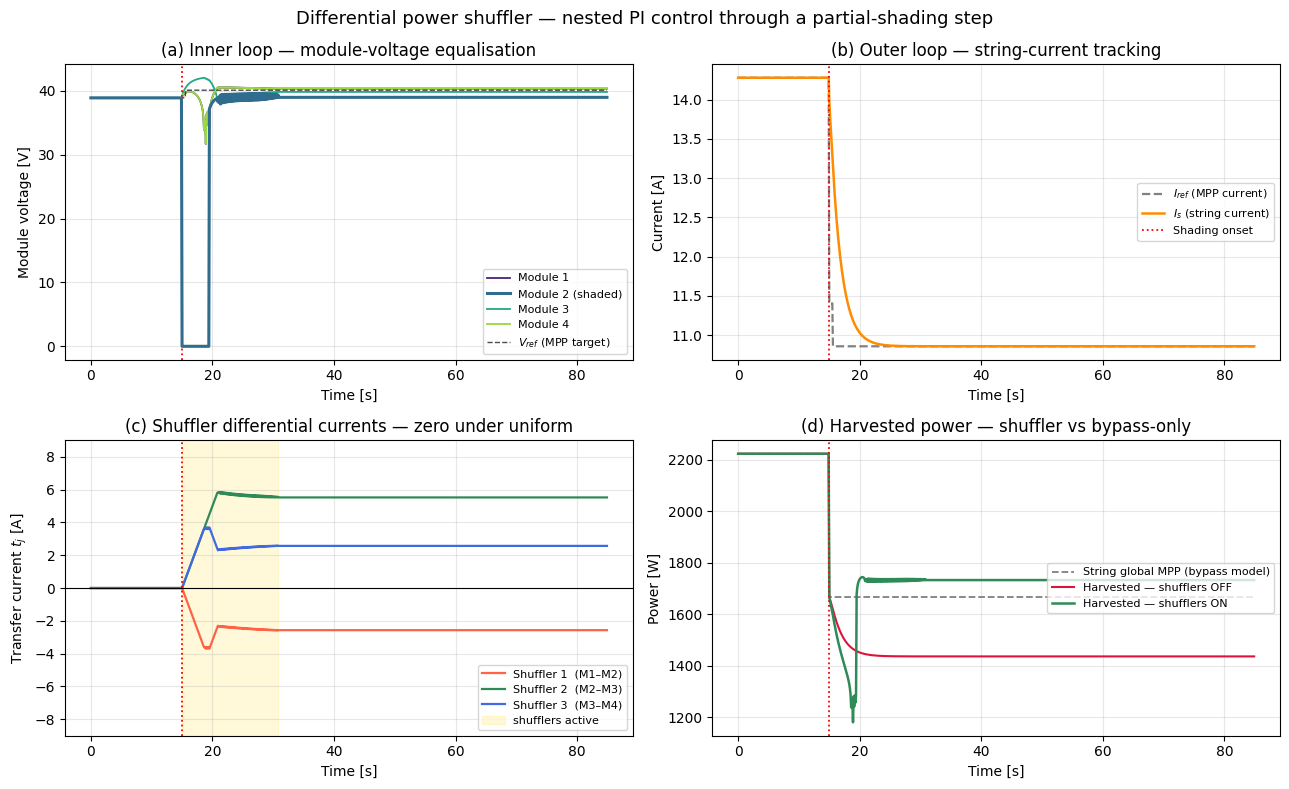

In [15]:
DT_SH    = 0.1                     # s per control step
N_UNI    = 150                     # uniform steps  (15 s)
N_SHADE_ = 700                     # shaded steps   (70 s)
G_UNIFORM = 1000.0
G_SHADE_M2 = [1000.0, 200.0, 1000.0, 1000.0]   # Module 2 shaded

schedule = [[G_UNIFORM] * 4] * N_UNI + [G_SHADE_M2] * N_SHADE_


def make_sim():
    string = PVString(4)
    shufs  = [Shuffler(f'S{j+1}') for j in range(3)]
    eq     = VoltageEqualizer(4)
    # MPPT held (mppt_every huge) so the two shuffler PI loops are shown cleanly;
    # the P&O supervisory loop was exercised in sections 7-11.
    return string, ShufflerSim(string, shufs, eq, dt_s=DT_SH, mppt_every=10**9)


string_on,  sim_on  = make_sim()
string_off, sim_off = make_sim()
H_on  = sim_on.run(schedule, shufflers_on=True)
H_off = sim_off.run(schedule, shufflers_on=False)

t_s     = np.arange(len(schedule)) * DT_SH       # seconds
t_event = N_UNI * DT_SH
_mcols  = plt.cm.viridis(np.linspace(0.1, 0.85, 4))

fig, ax = plt.subplots(2, 2, figsize=(13, 8))

# (a) inner loop -- module-voltage equalisation
for m in range(4):
    style = dict(lw=2.2, zorder=4) if m == 1 else dict(lw=1.3)
    lbl   = f'Module {m+1}' + (' (shaded)' if m == 1 else '')
    ax[0, 0].plot(t_s, H_on['v_mod'][:, m], color=_mcols[m], label=lbl, **style)
ax[0, 0].plot(t_s, H_on['v_ref'], 'k--', lw=1.0, alpha=0.7, label='$V_{ref}$ (MPP target)')
ax[0, 0].axvline(t_event, color='r', ls=':', lw=1.3)
ax[0, 0].set_title('(a) Inner loop — module-voltage equalisation')
ax[0, 0].set_ylabel('Module voltage [V]'); ax[0, 0].set_xlabel('Time [s]')
ax[0, 0].legend(fontsize=8, loc='lower right'); ax[0, 0].grid(alpha=0.3)

# (b) outer loop -- string-current tracking
ax[0, 1].plot(t_s, H_on['i_ref'], color='grey', ls='--', lw=1.6, label='$I_{ref}$ (MPP current)')
ax[0, 1].plot(t_s, H_on['i_s'],  color='darkorange', lw=1.8, label='$I_s$ (string current)')
ax[0, 1].axvline(t_event, color='r', ls=':', lw=1.3, label='Shading onset')
ax[0, 1].set_title('(b) Outer loop — string-current tracking')
ax[0, 1].set_ylabel('Current [A]'); ax[0, 1].set_xlabel('Time [s]')
ax[0, 1].legend(fontsize=8, loc='center right'); ax[0, 1].grid(alpha=0.3)

# (c) shuffler differential currents -- off under uniform
_scols = ['tomato', 'seagreen', 'royalblue']
for j in range(3):
    ax[1, 0].plot(t_s, H_on['t'][:, j], color=_scols[j], lw=1.6,
                  label=f'Shuffler {j+1}  (M{j+1}–M{j+2})')
ax[1, 0].fill_between(t_s, -12, 12, where=H_on['active'] > 0.5,
                      color='gold', alpha=0.15, label='shufflers active')
ax[1, 0].axhline(0, color='k', lw=0.8)
ax[1, 0].axvline(t_event, color='r', ls=':', lw=1.3)
ax[1, 0].set_ylim(-9, 9)
ax[1, 0].set_title('(c) Shuffler differential currents — zero under uniform')
ax[1, 0].set_ylabel('Transfer current $t_j$ [A]'); ax[1, 0].set_xlabel('Time [s]')
ax[1, 0].legend(fontsize=8, loc='lower right'); ax[1, 0].grid(alpha=0.3)

# (d) harvested power -- shuffler vs bypass-only
ax[1, 1].plot(t_s, H_on['p_avail'], color='grey', ls='--', lw=1.3,
              label='String global MPP (bypass model)')
ax[1, 1].plot(t_s, H_off['p_string'], color='crimson', lw=1.5,
              label='Harvested — shufflers OFF')
ax[1, 1].plot(t_s, H_on['p_string'],  color='seagreen', lw=1.8,
              label='Harvested — shufflers ON')
ax[1, 1].axvline(t_event, color='r', ls=':', lw=1.3)
ax[1, 1].set_title('(d) Harvested power — shuffler vs bypass-only')
ax[1, 1].set_ylabel('Power [W]'); ax[1, 1].set_xlabel('Time [s]')
ax[1, 1].legend(fontsize=8, loc='center right'); ax[1, 1].grid(alpha=0.3)

fig.suptitle('Differential power shuffler — nested PI control through a partial-shading step',
             fontsize=13)
fig.tight_layout()
plt.show()

## 15 · Controller convergence & power recovery

The two panels below isolate each loop's error signal so the closed-loop response
is unambiguous: the **inner-loop** module-voltage spread $\max_k V_k-\min_k V_k$
collapses from the bypass-induced step back into the equalisation band, and the
**outer-loop** current error $|I_{ref}-I_s|$ decays to zero. The bar chart and
printout quantify the recovered power against the bypass-only baseline and the
per-module MPP ceiling.

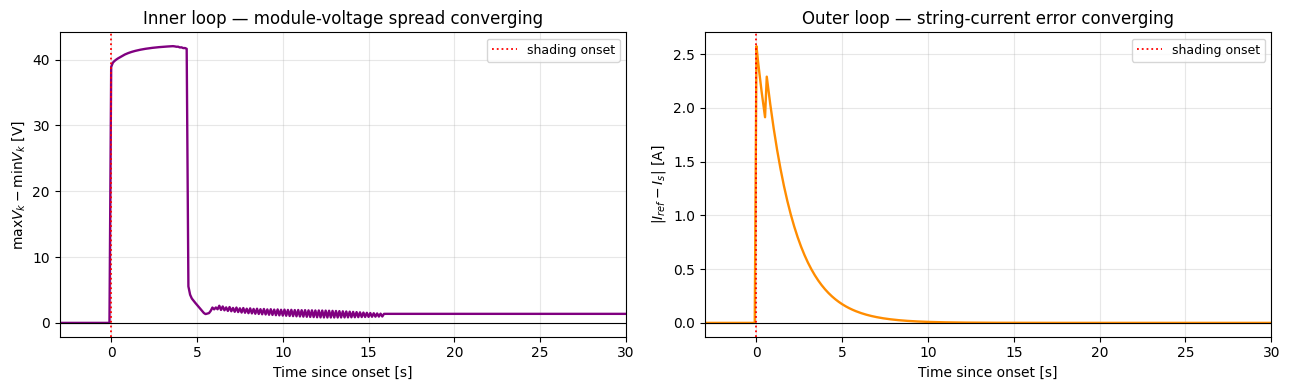

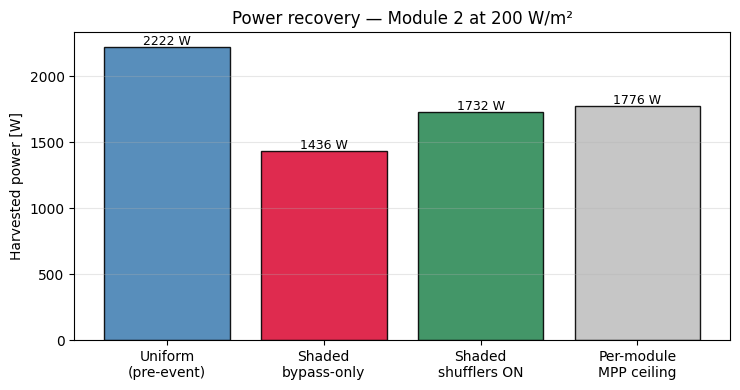

Steady-state, Module 2 @ 200 W/m²:
  module voltages [V] : [40.4 39.  39.8 40.4]
  module currents [A] : [13.43  2.77 13.81 13.43]
  transfer currents[A]: [-2.57  5.52  2.57]
  string current   [A]: 10.86

  harvested  shufflers OFF :  1436.4 W   (80.9% of per-module MPP)
  harvested  shufflers ON  :  1732.4 W   (97.6% of per-module MPP)
  recovered by shufflers   :   296.0 W   (+20.6%)
  differential power moved :   422.4 W   (24.4% of string power -> only the mismatch)


In [16]:
k_on  = N_UNI                               # first shaded step
k_end = len(schedule) - 1
t_rel = (t_s - t_event)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))

# inner-loop convergence: module-voltage spread
spread_on = H_on['v_mod'].max(axis=1) - H_on['v_mod'].min(axis=1)
ax[0].plot(t_rel, spread_on, color='purple', lw=1.7)
ax[0].axhline(0, color='k', lw=0.8)
ax[0].axvline(0, color='r', ls=':', lw=1.3, label='shading onset')
ax[0].set_xlim(-3, 30)
ax[0].set_title('Inner loop — module-voltage spread converging')
ax[0].set_ylabel('$\\max V_k - \\min V_k$ [V]'); ax[0].set_xlabel('Time since onset [s]')
ax[0].legend(fontsize=9); ax[0].grid(alpha=0.3)

# outer-loop convergence: string-current error
ierr = np.abs(H_on['i_ref'] - H_on['i_s'])
ax[1].plot(t_rel, ierr, color='darkorange', lw=1.7)
ax[1].axhline(0, color='k', lw=0.8)
ax[1].axvline(0, color='r', ls=':', lw=1.3, label='shading onset')
ax[1].set_xlim(-3, 30)
ax[1].set_title('Outer loop — string-current error converging')
ax[1].set_ylabel('$|I_{ref} - I_s|$ [A]'); ax[1].set_xlabel('Time since onset [s]')
ax[1].legend(fontsize=9); ax[1].grid(alpha=0.3)

fig.tight_layout()
plt.show()

# ---- per-module MPP ceiling for the shaded scenario ----
_ceil_string = PVString(4)
_ceil_string.set_conditions(G_SHADE_M2)
p_ceiling = sum(m.iv_curve['p_mp'] for m in _ceil_string.modules)

p_uni    = H_on['p_string'][k_on - 1]
p_sh_on  = H_on['p_string'][k_end]
p_sh_off = H_off['p_string'][k_end]

fig, axb = plt.subplots(figsize=(7.5, 4))
labels = ['Uniform\n(pre-event)', 'Shaded\nbypass-only', 'Shaded\nshufflers ON',
          'Per-module\nMPP ceiling']
vals   = [p_uni, p_sh_off, p_sh_on, p_ceiling]
bcols  = ['steelblue', 'crimson', 'seagreen', 'silver']
bars = axb.bar(labels, vals, color=bcols, edgecolor='k', alpha=0.9)
for b, v in zip(bars, vals):
    axb.text(b.get_x() + b.get_width() / 2, v + 15, f'{v:.0f} W', ha='center', fontsize=9)
axb.set_ylabel('Harvested power [W]')
axb.set_title('Power recovery — Module 2 at 200 W/m²')
axb.grid(alpha=0.3, axis='y')
fig.tight_layout()
plt.show()

recovered = p_sh_on - p_sh_off
print('Steady-state, Module 2 @ 200 W/m²:')
print(f'  module voltages [V] : {np.array2string(H_on["v_mod"][k_end], precision=1)}')
print(f'  module currents [A] : {np.array2string(H_on["i_mod"][k_end], precision=2)}')
print(f'  transfer currents[A]: {np.array2string(H_on["t"][k_end], precision=2)}')
print(f'  string current   [A]: {H_on["i_s"][k_end]:.2f}')
print()
print(f'  harvested  shufflers OFF : {p_sh_off:7.1f} W   ({100*p_sh_off/p_ceiling:4.1f}% of per-module MPP)')
print(f'  harvested  shufflers ON  : {p_sh_on:7.1f} W   ({100*p_sh_on/p_ceiling:4.1f}% of per-module MPP)')
print(f'  recovered by shufflers   : {recovered:7.1f} W   (+{100*recovered/p_sh_off:4.1f}%)')
print(f'  differential power moved : {H_on["p_shuf"][k_end]:7.1f} W   '
      f'({100*H_on["p_shuf"][k_end]/p_sh_on:4.1f}% of string power -> only the mismatch)')